__Tasks:__
- [x] Collect a MVD (Minimum Viable Data)
    - I'm using the raw data for MOLM-13 screen from this [bioRxiv](https://www.biorxiv.org/content/10.1101/2022.12.14.518457v1)
- [x] Trim reads in FASTQ, count unique sequences, and map to V2 sgRNA library table.
- [ ] Compare with ScreenProcessing

___
    Thu Mar  7 03:55:05 UTC 2024

I have implmented all required features for single-guide and dual-guide designs. Here I want to perform enough tests to make sure I have everything ready to go for other users!

In [103]:
!pip uninstall -y screenpro2

Found existing installation: ScreenPro2 0.2.7
Uninstalling ScreenPro2-0.2.7:
  Successfully uninstalled ScreenPro2-0.2.7


In [104]:
!pip install git+https://github.com/arcinstitute/screenpro2.git@dual-guide-design

  Cloning https://github.com/arcinstitute/screenpro2.git (to revision dual-guide-design) to /var/tmp/pip-req-build-zbqf1k1c
  Running command git clone --filter=blob:none --quiet https://github.com/arcinstitute/screenpro2.git /var/tmp/pip-req-build-zbqf1k1c
  Running command git checkout -b dual-guide-design --track origin/dual-guide-design
  Switched to a new branch 'dual-guide-design'
  Branch 'dual-guide-design' set up to track remote branch 'dual-guide-design' from 'origin'.
  Resolved https://github.com/arcinstitute/screenpro2.git to commit 7dd75feed0996a468ba88769a490a442208c3420
  Preparing metadata (setup.py) ... done
  Created wheel for ScreenPro2: filename=ScreenPro2-0.2.7-py3-none-any.whl size=17557 sha256=76305b19df920ddbbeec44c56bfe6181827d528834aac62576030e7fba9f6489
  Stored in directory: /var/tmp/pip-ephem-wheel-cache-ax1xrvll/wheels/d0/dd/a5/c86105c535874faed663579ec82be8dc9d873222ba52cc112c
Successfully built ScreenPro2


In [1]:
from screenpro import ngs

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import biobear as bb
import anndata as ad
import polars as pl
from time import time
from glob import glob

# from pyfaidx import Fasta

# Collect data
A Minimum Viable Data (MVD)!

In [3]:
import subprocess 

In [4]:
# %%bash 
# mkdir -p DDRi_PRDX1_screens_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v3/DDRi-PRDX1-screens/`; do
#     b=`basename $fq`;
#     echo $b;
#     gsutil cp $fq DDRi_PRDX1_screens_fastq/$b;
# done

In [5]:
# %%bash 
# mkdir -p molm13_exp_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v2/molm13_exp`; do
#     b=`basename $fq`;
#     gsutil cp $fq molm13_exp_fastq/$b;
# done

In [6]:
def oligo_sequence_design():
    """
    """
    ## assuming R1=19, R2=19
    r1 = 'G'+19*'N'
    r2 = 19*'N'
    # r1 = 'G'+19*'N'
    print(f'oligo: {len(r1)*"A"}{len(r2)*"B"}')
    print(f'read1: {r1}{len(r2)*"-"}, length: {len(r1)}')
    print(f'read2: {len(r1)*"-"}{r2}, length: {len(r1)}')
    print()    
    print('A: protospacer A')
    print('B: protospacer B')


In [7]:
oligo_sequence_design()

oligo: AAAAAAAAAAAAAAAAAAAABBBBBBBBBBBBBBBBBBB
read1: GNNNNNNNNNNNNNNNNNNN-------------------, length: 20
read2: --------------------NNNNNNNNNNNNNNNNNNN, length: 20

A: protospacer A
B: protospacer B


## CRISPRi_v3

### Count FASTQ ...

In [8]:
res = ngs.fastq_to_count_dual_guide(
    R1_fastq_file_path='DDRi_PRDX1_screens_fastq/i01_R1.fastq.gz',
    R2_fastq_file_path='DDRi_PRDX1_screens_fastq/i01_R2.fastq.gz',
    trim5p_pos1_start=1,
    trim5p_pos1_length=19,
    trim5p_pos2_start=1,
    trim5p_pos2_length=19    
)

In [9]:
res = res.sort('count', descending=True)

In [11]:
res = res.with_columns(
    pl.concat_str(
        [
            pl.col("protospacer_a"),
            pl.col("protospacer_b")
        ],
        separator=";",
    ).alias("sequence"),
)

___

In [39]:
library = pd.read_csv(
    'CRISPRi_dual_human_librarytable_corrected_v2.txt',
    sep='\t',low_memory=False
).rename(
    columns={'protospacer_A':'protospacer_a','protospacer_B':'protospacer_b'}
)

library['sequence'] = library.protospacer_a.str[1:] + ';' + library.protospacer_b.str[1:]
library.protospacer_a = library.protospacer_a.str[1:]
library.protospacer_b = library.protospacer_b.str[1:]

In [67]:
library_top12 = library.query(
    "predictedRank_A not in ['3','5'] & predictedRank_B not in ['4','6']"
).reset_index(drop=True)

In [40]:
# ngs.map_sample_counts_to_library(
#     sample=res.to_pandas(),
#     library=library
# )

In [41]:
res_map = pl.DataFrame(library).join(
        res, on="sequence", how="left"
    )

In [82]:
# {'inner', 'left', 'outer', 'semi', 'anti', 'cross'}

res_unmap = res.join(
        pl.DataFrame(library), on="sequence", how="anti"
    )

In [87]:
100 * \
res_unmap.to_pandas()['count'].fillna(0).sum() / \
int(res.select(pl.sum("count")).to_pandas()['count'])

43.33733729867203

In [42]:
100 * \
res_map.to_pandas()['count'].fillna(0).sum() / \
int(res.select(pl.sum("count")).to_pandas()['count'])

57.532009355339234

In [98]:
res_unmap_remapped_a = res_unmap.join(
    pl.DataFrame(library[['sgID_A','protospacer_a']]), on=["protospacer_a"], how="left"
)

In [107]:
res_unmap_remapped_a.join(
    pl.DataFrame(library[['sgID_B','protospacer_b']]), 
    on=["protospacer_b"], how="left"
).drop_nulls().filter(pl.col("count") > 10)

protospacer_a,protospacer_b,count,sequence,sgID_A,sgID_B
str,str,i64,str,str,str
"""CAAGAGCTAGCCTC…","""CACCGACCGGCACC…",11320,"""CAAGAGCTAGCCTC…","""MLF1_+_1582889…","""UFSP1_-_100487…"
"""CGGGGCCCGCCGCA…","""TGGAGAGCAGGGTC…",269,"""CGGGGCCCGCCGCA…","""NT5C2_-_104952…","""PROC_-_1281764…"
"""GGCCTGCCGGGAGT…","""CTCCTGGGGAGCGC…",221,"""GGCCTGCCGGGAGT…","""NOL11_-_657140…","""ZGPAT_+_623388…"
"""GGAGCTAGGCCGGC…","""GTCGGCCGCCCTAG…",211,"""GGAGCTAGGCCGGC…","""ERAP1_+_961436…","""IFT140_-_16606…"
"""CAGCTCTGGAGTCA…","""GAGCTGACGCCAAG…",168,"""CAGCTCTGGAGTCA…","""GPR85_+_112726…","""SLC38A8_+_8407…"
"""CACGCTGGGTGATC…","""GGCAGTCTTCCGAG…",161,"""CACGCTGGGTGATC…","""C10orf62_+_993…","""EMC6_-_3572123…"
"""CTCAAGGCCGGAGA…","""AGCTCCTAGGACCA…",159,"""CTCAAGGCCGGAGA…","""KIAA2018_-_113…","""SLC34A3_-_1401…"
"""CCGCTGAACCCGGA…","""AGGAGCAGTTCTCA…",149,"""CCGCTGAACCCGGA…","""IMPA1_-_825984…","""SMPX_+_2177621…"
"""ACAGCGTGAAAGGA…","""AAACTGAGACAGTA…",149,"""ACAGCGTGAAAGGA…","""DDX50_+_706610…","""C3AR1_-_821889…"


**conclusion**: these steps could capture recombination events and retain information about 40% of dismissed reads!

## CRISPRi_v2

### Count FASTQ ...

In [12]:
# !wget https://raw.githubusercontent.com/mhorlbeck/ScreenProcessing/master/library_reference/CRISPRi_v2_human.trim_1_29_forward.fa

# !mkdir -p ../../../ScreenPro2/library_reference
# !mv CRISPRi_v2_human.trim_1_29_forward.fa \
#     ../../../ScreenPro2/library_reference/CRISPRi_v2_human.trim_1_29_forward.fasta

In [13]:
fasta_file_path = '../../../ScreenPro2/library_reference/CRISPRi_v2_human.trim_1_29_forward.fasta'

In [14]:
ls '../../../ScreenPro2/library_reference'

CRISPRi_v2_human.trim_1_29_forward.fasta


In [15]:
# !cat {fasta_file_path} | wc -l

In [16]:
library = bb.FastaReader(fasta_file_path)

In [17]:
# library_fa = Fasta(fasta_file_path)

In [18]:
# pd.DataFrame([ (sgId, str(seq)) for sgId, seq in library_fa.items()],columns=['sgId','sequence'])

In [19]:
# library_fa.keys()

In [20]:
# library = pd.DataFrame(library_fa.items())

In [21]:
# library

In [22]:
library = pd.read_csv('../../../ScreenPro2/library_tables/CRISPRi_v2_human_librarytable.txt.gz',sep='\t')
library.sequence = library.sequence.str.upper().str[1:]

library_full = library.copy()

library = library.drop_duplicates('sequence',keep='first').set_index('sequence')

### Get Counts

Note: `Upper` helped to increase the mapping efficiency!

In [23]:
slice_seq = (2,19)

In [24]:
counts = {}

start, length = slice_seq

for fq_file in glob('molm13_exp_fastq/*'):
    sample_id = fq_file.split('/')[1].split('.')[0]
    
    print(f"\033[1m{sample_id}\033[0m")
    t0 = time()
    
    session = bb.connect()

    print("start counting ...")
    
    df_cnt = session.sql(f"""
    SELECT substr(f.sequence, {start}, {length}) AS sequence, COUNT(*) as count
    FROM fastq_scan('{fq_file}') f
    GROUP BY substr(f.sequence, {start}, {length})
    """
    ).to_polars()    
    
    df_cnt = df_cnt.to_pandas()
    print(f'# of sequences: {df_cnt.shape[0]}')
    print(f'total counts: {df_cnt["count"].sum()}')
    
    df_mapped = ngs.map_sample_counts_to_library(library,df_cnt)
    
    counts[sample_id] = df_mapped
    
    print("done in %0.3fs" % (time() - t0))

DMSO_Rep2
start counting ...
# of sequences: 1231293
total counts: 89965203
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 77.384s
T0_Rep1
start counting ...
# of sequences: 1340346
total counts: 88608358
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 77.443s
DAC_Rep1
start counting ...
# of sequences: 1168186
total counts: 87165105
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 75.859s
DMSO_Rep1
start counting ...
# of sequences: 1370378
total counts: 100710735
% mapped sequences: 0.89
% non-mapped sequences: 0.11
done in 88.455s
DAC_Rep2
start counting ...
# of sequences: 1273923
total counts: 81834220
% mapped sequences: 0.89
% non-mapped sequences: 0.11
done in 72.046s
DMSO_Rep2
start counting ...
# of sequences: 56765
total counts: 100000
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done in 0.382s
T0_Rep2
start counting ...
# of sequences: 1465160
total counts: 94726489
% mapped sequences: 0.90
% non-mapped sequences: 0.10
done

/home/jupyter/CRISPR-projects/ScreenPro-Benchmarking/analysis/1a-dCas9-genome-scale-libraries/../../../ScreenPro2/screenpro/ngs.py:63: RuntimeWarning: invalid value encountered in scalar divide
  print(f"% mapped sequences: {n_mapped_counts/sample['count'].sum():.2f}")
/home/jupyter/CRISPR-projects/ScreenPro-Benchmarking/analysis/1a-dCas9-genome-scale-libraries/../../../ScreenPro2/screenpro/ngs.py:64: RuntimeWarning: invalid value encountered in scalar divide
  print(f"% non-mapped sequences: {n_unmapped_counts/sample['count'].sum():.2f}")


### Make `AnnData`

In [58]:
counts['DMSO_Rep1']

,sgId,sublibrary,gene,transcripts,counts
sequence,,,,,
GAGACCCAGCGCTAACCAG,A1BG_-_58858617.23-P1,h3_top5,A1BG,P1,203
GGGCACCCAGGAGCGGTAG,A1BG_-_58858788.23-P1,h3_top5,A1BG,P1,359
CTCCGGGCGACGTGGAGTG,A1BG_+_58858964.23-P1,h3_top5,A1BG,P1,513
AACCAGGGGTGCCCAAGGG,A1BG_-_58858630.23-P1,h3_top5,A1BG,P1,328
GCGAGGAACCGCCCAGCAA,A1BG_+_58858549.23-P1,h3_top5,A1BG,P1,223
...,...,...,...,...,...
CTACTCCGCCCCGCGGGAG,non-targeting_03785,h7_supp5,negative_control,na,0
TGGCCGTTCATGGGACCGG,non-targeting_03786,h7_supp5,negative_control,na,0
AACTCTGTAGAAGGGACCG,non-targeting_03787,h7_supp5,negative_control,na,0


In [27]:
counts_df = pd.concat(dict([(name,df['counts']) for name, df in counts.items()]),axis=1)

In [28]:
adata = ad.AnnData(X=counts_df.T,var=library)

adata = adata[:,adata.to_df().sum().gt(0)].copy()

### Compare counts with ScreenProcessing

In [29]:
# !wget 'https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/molm13_exp/mergedcountstable.txt'

In [30]:
screenprocessing_counts = pd.read_csv(
    'mergedcountstable.txt', 
    sep='\t', 
    header=list(range(2)),
    index_col=list(range(1))
)

screenprocessing_counts = screenprocessing_counts[screenprocessing_counts.sum(axis=1).gt(0)]

In [31]:
from venn import venn

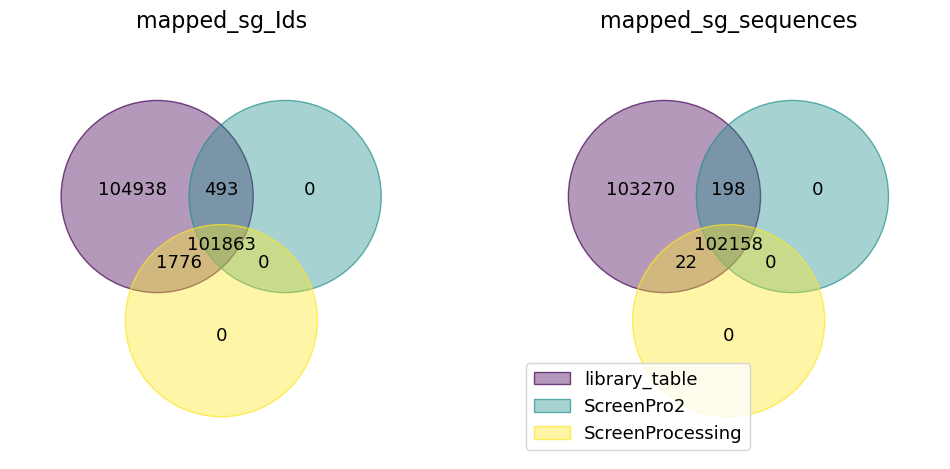

In [32]:
fig,(ax,bx) = plt.subplots(1,2,figsize=(12,6))
venn({
    'library_table':set(library_full.sgId),
    'ScreenPro2':set(adata.var.sgId),
    'ScreenProcessing':set(screenprocessing_counts.index)#.loc[adata.var.sgId,:]
},legend_loc=None,ax=ax)
ax.set_title('mapped_sg_Ids',fontsize=16)

venn({
    'library_table':set(library_full.sequence),
    'ScreenPro2':set(adata.var.index),
    'ScreenProcessing':set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list())
},legend_loc='best',ax=bx)
bx.set_title('mapped_sg_sequences',fontsize=16)
plt.show()

In [33]:
# set(adata.var.sgId) - set(screenprocessing_counts.index)#.loc[adata.var.sgId,:]

In [34]:
tmp1 = set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list()) - set(adata.var.index)

In [35]:
sorted_tmp = adata[:,list(set(adata.var.index) - set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list()))].to_df().sum().sort_values().index

In [36]:
fq_file

'molm13_exp_fastq/DMSO_Rep2.fasta.gz'

In [37]:
# fq2fa_file = fq_file.replace('fastq.gz','fasta.gz')

In [38]:
# !seqkit fq2fa -j 6 {fq_file} -o {fq2fa_file}

In [39]:
# # df_fq = ngs.fastq_to_dataframe(
#     fq_file,
#     engine='biobear'
# )

In [40]:
# !zcat {fq_file} | wc -l 

In [41]:
# 378905956 / 4

In [42]:
# df_fq = bb.FastqReader(fq_file,compression=Compression.GZIP).to_polars()

In [43]:
# df_fq.shape

In [44]:
# screenprocessing_counts['T0']['Rep2'].sum() / 89965203

In [45]:
# adata.to_df().loc['T0_Rep2'].sum() / 89965203

<AxesSubplot: >

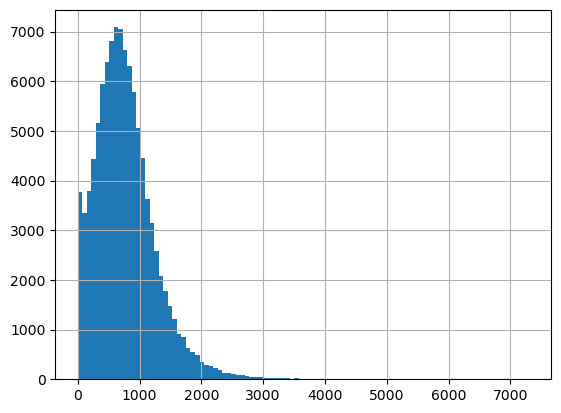

In [ ]:
screenprocessing_counts['T0']['Rep1'].hist(bins=100)

<AxesSubplot: >

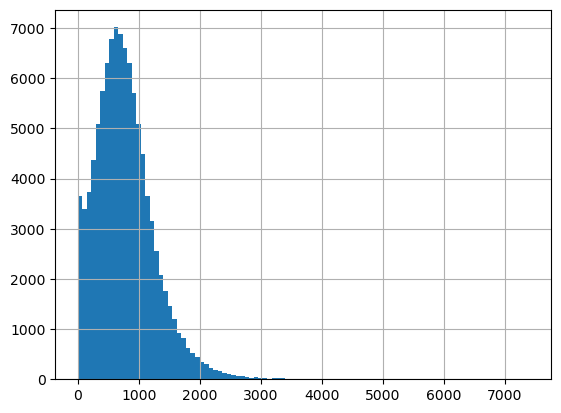

In [ ]:
adata.to_df().loc['T0_Rep1'].hist(bins=100)

In [50]:
screenprocessing_counts['T0']['Rep1']

sgId
A1BG_+_58858549.23-P1     428
A1BG_+_58858964.23-P1     518
A1BG_+_58864367.23-P2     875
A1BG_-_58858617.23-P1     303
A1BG_-_58858630.23-P1     435
                         ... 
non-targeting_01889      1151
non-targeting_01890       545
non-targeting_01892       686
non-targeting_01893      1318
non-targeting_01894      1274
Name: Rep1, Length: 103639, dtype: int64

In [55]:
adata.var.set_index()#.loc['T0_Rep1']

,sgId,sublibrary,gene,transcripts
sequence,,,,
GAGACCCAGCGCTAACCAG,A1BG_-_58858617.23-P1,h3_top5,A1BG,P1
GGGCACCCAGGAGCGGTAG,A1BG_-_58858788.23-P1,h3_top5,A1BG,P1
CTCCGGGCGACGTGGAGTG,A1BG_+_58858964.23-P1,h3_top5,A1BG,P1
AACCAGGGGTGCCCAAGGG,A1BG_-_58858630.23-P1,h3_top5,A1BG,P1
GCGAGGAACCGCCCAGCAA,A1BG_+_58858549.23-P1,h3_top5,A1BG,P1
...,...,...,...,...
GCCCGCCGACAAAGGTTGG,non-targeting_01890,h7_top5,negative_control,na
AAGGCGCCTCGTATAAGGC,non-targeting_01892,h7_top5,negative_control,na
GACACGGGCGAAGGGATAA,non-targeting_01893,h7_top5,negative_control,na


In [48]:
# adata.var.sgId.to_list()

In [49]:
# screenprocessing_counts#.loc[adata.var.sgId,:]

In [66]:
def plot_count_benchmark():
    pass
    #screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

In [68]:
plot_count_benchmark()

# 

In [25]:
%load_ext watermark
%watermark
%watermark --iversions

Last updated: 2024-02-28T20:57:25.453134+00:00

Python implementation: CPython
Python version       : 3.9.18
IPython version      : 8.18.1

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 5.10.0-28-cloud-amd64
Machine     : x86_64
Processor   : 
CPU cores   : 16
Architecture: 64bit

polars    : 0.20.10
sys       : 3.9.18 (main, Sep 11 2023, 13:41:44) 
[GCC 11.2.0]
pandas    : 1.5.3
biobear   : 0.15.3
anndata   : 0.10.5.post1
matplotlib: 3.6.3
screenpro : 0.2.6

